In [1]:
# Importing the libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics                           
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA
import mglearn

In [2]:
# Importing the dataset
data_maternal= pd.read_csv("Maternal Health Risk Data Set.csv")
data_maternal.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
# Display number of rows and columns
data_maternal.shape

(1014, 7)

In [4]:
# Look at check missing values
data_maternal.isnull().sum()

Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

In [5]:
# Look at basic information
data_maternal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64


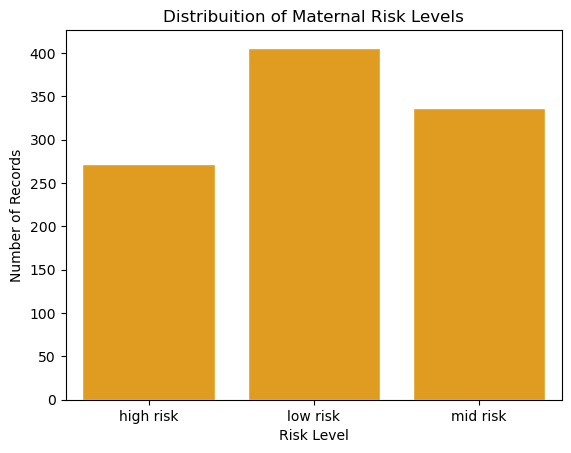

In [6]:
# Distribuition Risk Levels 
print (data_maternal["RiskLevel"].value_counts())
sns.countplot(data=data_maternal, x="RiskLevel",color="Orange",edgecolor="white")

plt.title("Distribuition of Maternal Risk Levels")
plt.xlabel("Risk Level")
plt.ylabel("Number of Records")

plt.show()

In [7]:
# Target Variable of the Dataset

feature_cols = ['SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate','Age']
X = data_maternal[feature_cols]               
y = data_maternal['RiskLevel']                    

# Display the X and y arrays
print(X, y)

      SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  Age
0            130           80  15.0      98.0         86   25
1            140           90  13.0      98.0         70   35
2             90           70   8.0     100.0         80   29
3            140           85   7.0      98.0         70   30
4            120           60   6.1      98.0         76   35
...          ...          ...   ...       ...        ...  ...
1009         120           60  15.0      98.0         80   22
1010         120           90  18.0      98.0         60   55
1011          85           60  19.0      98.0         86   35
1012         120           90  18.0      98.0         70   43
1013         120           65   6.0     101.0         76   32

[1014 rows x 6 columns] 0       high risk
1       high risk
2       high risk
3       high risk
4        low risk
          ...    
1009    high risk
1010    high risk
1011    high risk
1012    high risk
1013     mid risk
Name: RiskLevel, Length: 1014, dt

In [8]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1) 

X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1014, 6), (1014,), (709, 6), (305, 6), (709,), (305,))

In [9]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion='gini', max_depth = 4, random_state = 0)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [10]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.6622950819672131
Accuracy: 0.66


In [11]:
X.columns.tolist()

['SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'Age']

In [12]:
data_maternal['RiskLevel'].unique().tolist()

['high risk', 'low risk', 'mid risk']

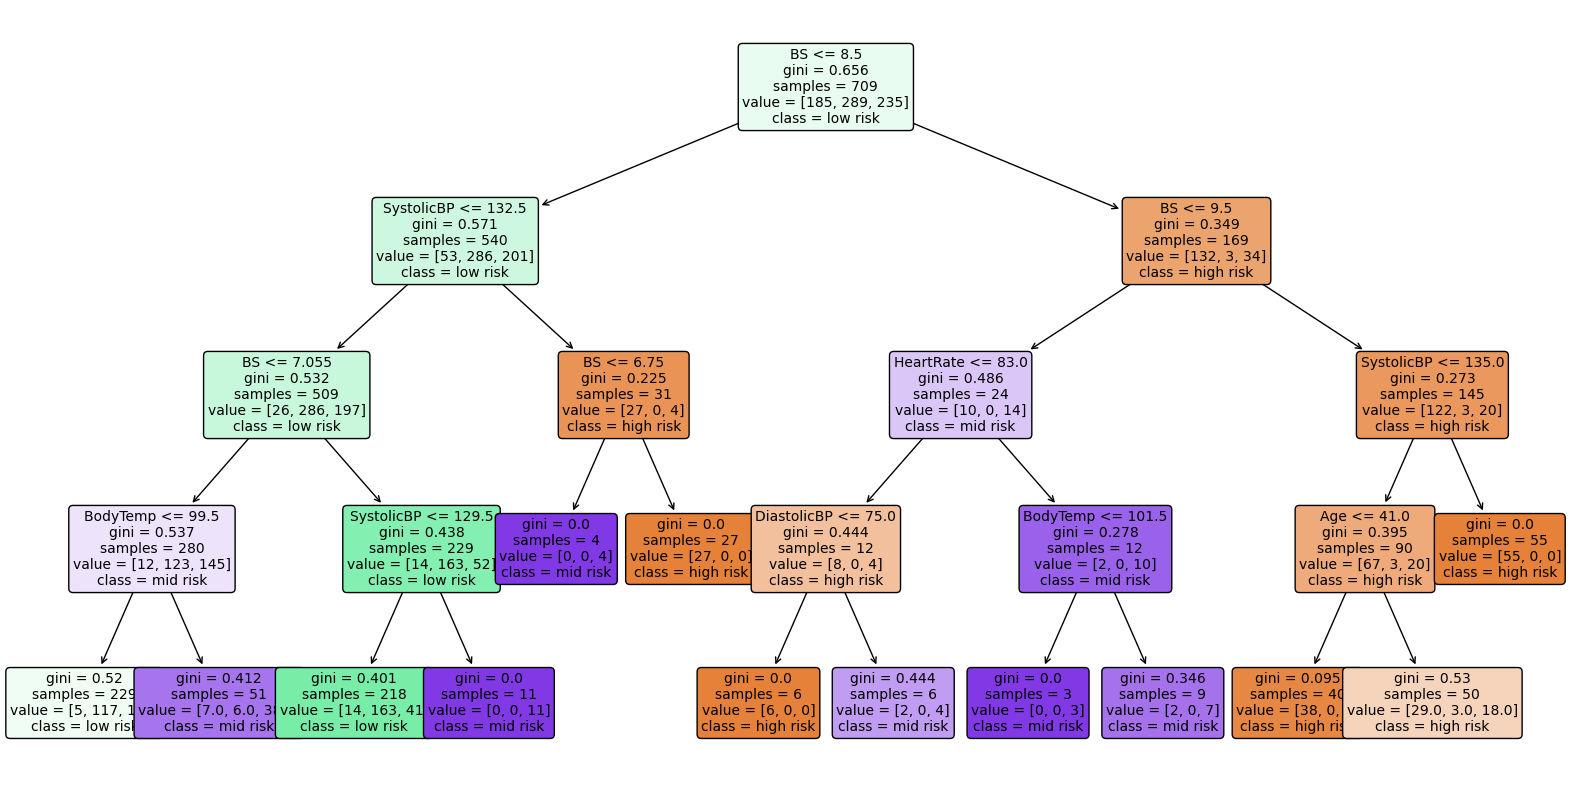

In [13]:
# Plot the Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(clf, filled=True, feature_names=X.columns.tolist(), class_names=[str(label) for label in data_maternal['RiskLevel'].unique()], rounded=True, fontsize=10)
plt.show()

In [14]:
#Define X and y 
X = data_maternal.drop("RiskLevel", axis=1)
y = data_maternal["RiskLevel"]

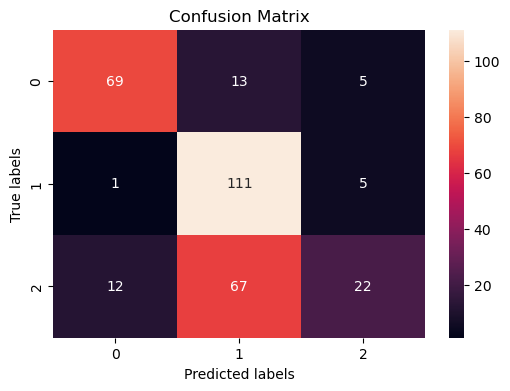

Classification Report:
              precision    recall  f1-score   support

   high risk       0.84      0.79      0.82        87
    low risk       0.58      0.95      0.72       117
    mid risk       0.69      0.22      0.33       101

    accuracy                           0.66       305
   macro avg       0.70      0.65      0.62       305
weighted avg       0.69      0.66      0.62       305



In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d')  # 'd' stands for integer format
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

In [16]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(random_state=42)

svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

In [17]:
results = []
for test_size in [0.05, 0.15, 0.25]:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    for name, model in [("Random Forest", rf), ("SVM", svm)]:

        scores = cross_val_score(
            model, X_train, y_train,
            cv=5,
            scoring="accuracy"
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        results.append({
            "Test Size": test_size,
            "Model": name,
            "CV Mean Accuracy": scores.mean(),
            "Test Accuracy": accuracy
        })

results_df = pd.DataFrame(results)
print(results_df)

   Test Size          Model  CV Mean Accuracy  Test Accuracy
0       0.05  Random Forest          0.825567       0.784314
1       0.05            SVM          0.700928       0.686275
2       0.15  Random Forest          0.842015       0.843137
3       0.15            SVM          0.697977       0.705882
4       0.25  Random Forest          0.818421       0.874016
5       0.25            SVM          0.686842       0.716535


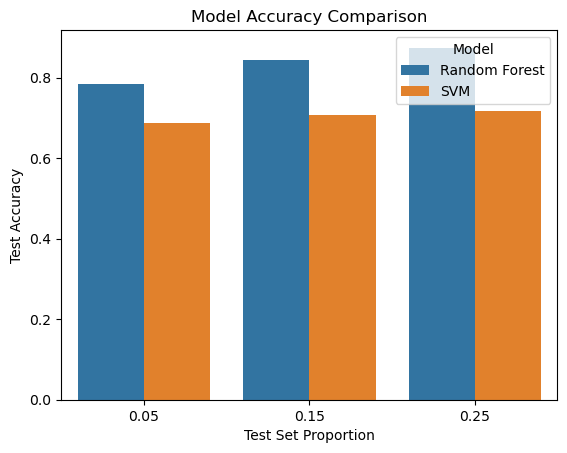

In [18]:
# Plot the Accuracy Comparison 
sns.barplot(
    data=results_df,
    x="Test Size",
    y="Test Accuracy",
    hue="Model"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.xlabel("Test Set Proportion")
plt.show()

In [19]:
#  Define Parameter Grid - Random Forest
from sklearn.model_selection import GridSearchCV  

rf = RandomForestClassifier(random_state=42)

param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

grid_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=5,
    scoring="accuracy"
)

grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best Cross Validation Accuracy:", grid_rf.best_score_)

rf_predictions = grid_rf.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, rf_predictions))

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best Cross Validation Accuracy: 0.8263157894736842
Test Accuracy: 0.8779527559055118


In [20]:
# Define Parameter Grid - SVM

svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

param_grid_svm = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

grid_svm = GridSearchCV(
    svm,
    param_grid_svm,
    cv=5,
    scoring="accuracy"
)

grid_svm.fit(X_train, y_train)

print("Best Parameters:", grid_svm.best_params_)
print("Best Cross Validation Accuracy:", grid_svm.best_score_)

svm_predictions = grid_svm.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, svm_predictions))

Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best Cross Validation Accuracy: 0.7
Test Accuracy: 0.7047244094488189


In [21]:
from sklearn.preprocessing import StandardScaler

# Create an object using Standard scalscaler
scaler = StandardScaler()

# Train the StandardScaler model
scaler.fit(X_train)

# transform data
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)
X_scaled = scaler.transform(X)

# print dataset after scaling
print(X_train_scaled, '\t', X_test_scaled, '\t', X_scaled)


[[-0.65956041 -1.24084753 -0.82542926 -0.56158731 -0.49336012  0.19302752]
 [ 1.35535393  0.36433396  0.25035599  0.67074958 -0.49336012  1.63127175]
 [-0.88343979 -1.50837778 -1.18402435 -0.38124532  1.66154615  1.39156437]
 ...
 [-0.43568104  0.36433396  0.25035599 -0.38124532 -0.49336012 -1.00550934]
 [-0.95806624 -1.50837778 -1.18402435 -0.74192929  2.37984824  1.39156437]
 [ 0.38520999 -0.70578703 -0.46683418 -0.56158731 -0.49336012 -1.72463146]] 	 [[ 0.23595707  0.09680371 -0.82542926 -0.53153031 -0.49336012 -0.5260946 ]
 [ 0.0120777   0.36433396  0.25035599 -0.56158731  1.66154615  0.19302752]
 [ 0.38520999 -0.70578703 -1.18402435  1.87302946 -0.49336012  0.67244226]
 ...
 [ 0.31058353  0.36433396 -0.1082391  -0.23096034 -0.49336012 -0.5260946 ]
 [-0.5103075   0.36433396  0.25035599 -0.38124532 -0.49336012 -0.5260946 ]
 [ 1.50460685  0.36433396  0.25035599 -0.32113133 -0.49336012 -0.5260946 ]] 	 [[-0.36105458  0.89939445  0.25035599  1.87302946 -0.49336012  1.39156437]
 [ 0.3852

In [22]:
# Keep The First Two Principal Components of The Data
pca = PCA(n_components = 2)

# transform data into the first two principal components
X_pca = pca.fit_transform(X_scaled)

print("Original shape: {}".format(str(X_scaled.shape)))
print("Reduced shape: {}".format(str(X_pca.shape)))

Original shape: (1014, 6)
Reduced shape: (1014, 2)


In [23]:
# PCA Variance
total_var = pca.explained_variance_ratio_.sum() * 100
print(X_pca, total_var)

[[ 1.39954828 -1.34396165]
 [ 2.09379198  0.37068374]
 [-1.25905394 -1.0802371 ]
 ...
 [ 0.23093903 -2.41886309]
 [ 2.43766501 -0.43029487]
 [-0.96523809 -0.70844998]] 62.47000917719143


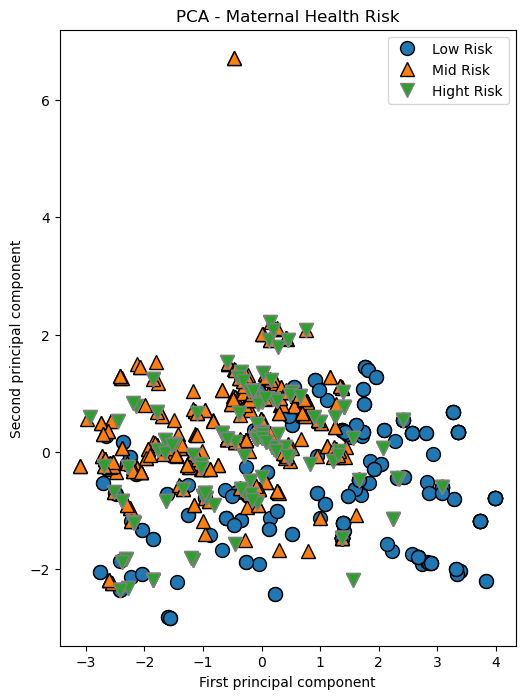

In [24]:
# Plot First VC Second Principal Component, Colored by Class
plt.figure(figsize = (8, 8))
mglearn.discrete_scatter(X_pca[:, 0], X_pca[:, 1], data_maternal["RiskLevel"])

plt.legend(["Low Risk","Mid Risk","Hight Risk"], loc="best")
plt.gca().set_aspect("equal")
plt.xlabel("First principal component")
plt.ylabel("Second principal component")

plt.title("PCA - Maternal Health Risk")
plt.show()

In [25]:
# PCA Components
print("PCA components:\n{}".format(pca.components_))

PCA components:
[[ 0.44527279  0.52359561  0.52348884  0.42476008 -0.26966483  0.01997422]
 [-0.18921757  0.12298206  0.13417363 -0.37023514 -0.45318408 -0.76721555]]


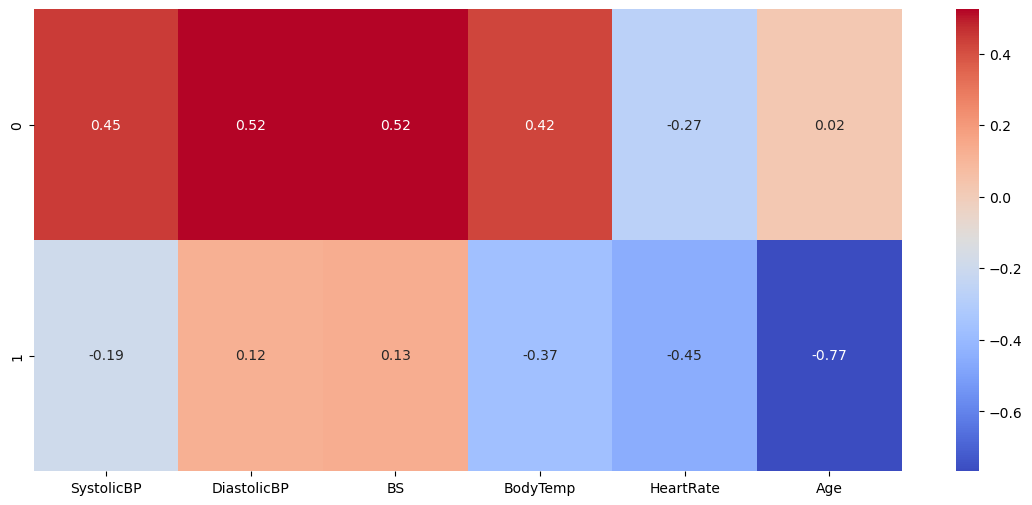

In [28]:
# Plot Heatmap
df_comp = pd.DataFrame(pca.components_, columns=feature_cols)

plt.figure(figsize=(14, 6))
sns.heatmap(df_comp, annot=True, cmap='coolwarm')
plt.show()